# Stage 1 — Infinite-width Gaussian-RBF predictor

Python/Jupyter conversion of `STAGE_01_INF_RBF_SPP_PAPER.m`. The numerical method, residual-attention construction, validation grid, and figures follow the MATLAB script. The stage output is saved as `STAGE_01_INF_RBF_SPP_attention_PAPER.npz` for use by Stage 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from pathlib import Path
from time import perf_counter

np.set_printoptions(precision=6, suppress=True)

def radical_inverse(n, b):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def exact_solution_spp(x, nu):
    x = np.asarray(x, dtype=float).reshape(-1)
    em = np.exp(-1.0 / nu)
    u = (np.exp((x - 1.0) / nu) - em) / (1.0 - em)
    u[np.isclose(x, 0.0)] = 0.0
    u[np.isclose(x, 1.0)] = 1.0
    return u

def kernel_raw(cfg, x, y, type1, type2):
    sigma = cfg['sigma_x']
    a = cfg['cx_a']
    b = cfg['cx_b']
    nu = cfg['nu']

    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)

    m = 0.5 * (x + y)
    d = x - y
    h = 0.5 * d

    za = a - m
    zb = b - m

    Ed = np.exp(-(d**2) / (4.0 * sigma**2))
    ea = np.exp(-(za / sigma)**2)
    eb = np.exp(-(zb / sigma)**2)

    I0 = 0.5 * sigma * np.sqrt(np.pi) * (erf(zb / sigma) - erf(za / sigma))
    I1 = 0.5 * sigma**2 * (ea - eb)
    I2 = 0.5 * sigma**2 * (za * ea - zb * eb) + 0.5 * sigma**2 * I0
    I3 = 0.5 * sigma**2 * (za**2 * ea - zb**2 * eb) + sigma**2 * I1
    I4 = 0.5 * sigma**2 * (za**3 * ea - zb**3 * eb) + 1.5 * sigma**2 * I2

    C = 1.0 / (b - a)

    if type1 == 'val' and type2 == 'val':
        return C * Ed * I0

    px0 = -h / sigma**2 - nu * h**2 / sigma**4 + nu / sigma**2
    px1 = 1.0 / sigma**2 + 2.0 * nu * h / sigma**4
    px2 = -nu / sigma**4

    py0 = h / sigma**2 - nu * h**2 / sigma**4 + nu / sigma**2
    py1 = 1.0 / sigma**2 - 2.0 * nu * h / sigma**4
    py2 = -nu / sigma**4

    if type1 == 'pde' and type2 == 'val':
        return C * Ed * (px0 * I0 + px1 * I1 + px2 * I2)
    if type1 == 'val' and type2 == 'pde':
        return C * Ed * (py0 * I0 + py1 * I1 + py2 * I2)
    if type1 == 'pde' and type2 == 'pde':
        c0 = px0 * py0
        c1 = px0 * py1 + px1 * py0
        c2 = px0 * py2 + px1 * py1 + px2 * py0
        c3 = px1 * py2 + px2 * py1
        c4 = px2 * py2
        return C * Ed * (c0 * I0 + c1 * I1 + c2 * I2 + c3 * I3 + c4 * I4)
    raise ValueError('Unknown kernel functional type.')

def compute_kernel_norm(cfg):
    xr = 0.5 * (cfg['XL'] + cfg['XR'])
    return float(kernel_raw(cfg, [xr], [xr], 'val', 'val')[0, 0])

def kernel_1d(cfg, x, y, type1, type2):
    return kernel_raw(cfg, x, y, type1, type2) / cfg['norm_const']

def predict_value(cfg, xP, xB, wP, wB, a, xq):
    NP = len(xP)
    aP = a[:NP]
    aB = a[NP:]
    KP = kernel_1d(cfg, xq, xP, 'val', 'pde')
    KB = kernel_1d(cfg, xq, xB, 'val', 'val')
    return (wP * KP) @ aP + (wB * KB) @ aB

def dilate_nonperiodic(mask, radius):
    mask = np.asarray(mask, dtype=bool)
    out = np.zeros_like(mask)
    for idx in np.flatnonzero(mask):
        j1 = max(0, idx - radius)
        j2 = min(mask.size, idx + radius + 1)
        out[j1:j2] = True
    return out

def attention_to_levels_nonperiodic(score, theta_mid, theta_high, high_radius, mid_radius):
    score = np.asarray(score, dtype=float).reshape(-1)
    if np.max(score) <= np.finfo(float).eps:
        return np.ones(score.size, dtype=int)
    high_raw = score >= theta_high
    mid_raw = score >= theta_mid
    if not np.any(high_raw):
        high_raw[np.argmax(score)] = True
    high_mask = dilate_nonperiodic(high_raw, high_radius)
    mid_mask = dilate_nonperiodic(mid_raw | high_raw, mid_radius)
    levels = np.ones(score.size, dtype=int)
    levels[mid_mask] = 2
    levels[high_mask] = 3
    return levels

def assemble_system(cfg, xP, xB, uB, wP, wB):
    KPP = kernel_1d(cfg, xP, xP, 'pde', 'pde')
    KPB = kernel_1d(cfg, xP, xB, 'pde', 'val')
    KBB = kernel_1d(cfg, xB, xB, 'val', 'val')
    Ktrain = np.block([[wP*wP*KPP, wP*wB*KPB],
                       [wB*wP*KPB.T, wB*wB*KBB]])
    Ktrain = 0.5 * (Ktrain + Ktrain.T)
    rhs = np.concatenate([np.zeros(len(xP)), wB * uB])
    return Ktrain, rhs

def spectral_solve(K, rhs, ridge_rel, eig_tol_rel):
    d, V = np.linalg.eigh(K)
    dmax = np.max(d)
    if dmax <= 0:
        raise ValueError('Kernel Gram matrix is not positive on the retained scale.')
    lam = ridge_rel * dmax
    keep = d > eig_tol_rel * dmax
    Vuse = V[:, keep]
    duse = d[keep] + lam
    coeff = Vuse @ ((Vuse.T @ rhs) / duse)
    return coeff, int(np.sum(keep)), float(lam)

def predict_residual(cfg, xP, xB, wP, wB, a, xq):
    NP = len(xP)
    aP = a[:NP]
    aB = a[NP:]
    KP = kernel_1d(cfg, xq, xP, 'pde', 'pde')
    KB = kernel_1d(cfg, xq, xB, 'pde', 'val')
    return (wP * KP) @ aP + (wB * KB) @ aB


## Problem and attention discretization

In [2]:
XL, XR = 0.0, 1.0
L = XR - XL
nu = 1e-3

NBx = 100
x_edges = np.linspace(XL, XR, NBx + 1)
Npde_per_block_pilot = 2
probe_n = 50

attention_rms_weight = 0.70
attention_max_weight = 0.30
theta_high = 0.35
theta_mid = 0.10
high_buffer_radius_x = 1
mid_buffer_radius_x = 2

sigma_x = 5.0e-4
cx_a = XL - 0.10 * L
cx_b = XR + 0.10 * L
ridge_rel = 1e-9
eig_tol_rel = 1e-13

## Uniform pilot collocation and kernel configuration

In [3]:
h01 = radical_inverse(np.arange(1, Npde_per_block_pilot + 1), 2)
xP = np.zeros(NBx * Npde_per_block_pilot)
block_id_P = np.zeros_like(xP, dtype=int)

kk = 0
for jx in range(NBx):
    xa, xb = x_edges[jx], x_edges[jx + 1]
    ids = slice(kk, kk + Npde_per_block_pilot)
    xP[ids] = xa + (xb - xa) * h01
    block_id_P[ids] = jx + 1
    kk += Npde_per_block_pilot

xB = np.array([XL, XR])
uB = np.array([0.0, 1.0])
Npde, Nbc = len(xP), len(xB)
wP, wB = 1 / np.sqrt(Npde), 1 / np.sqrt(Nbc)

kcfg = dict(sigma_x=sigma_x, cx_a=cx_a, cx_b=cx_b, nu=nu, XL=XL, XR=XR)
kcfg['norm_const'] = compute_kernel_norm(kcfg)

print('=============================================================')
print('STAGE 01: INFINITE-RBF SINGULAR-PERTURBATION PREDICTOR v3')
print('=============================================================')
print('No neuron count M and no quadrature order Q are used.')
print('No spatial interface losses are used.')
print(f'nu                           = {nu:.4e}')
print(f'Spatial attention blocks     = {NBx}')
print(f'Block width                  = {L/NBx:.4e}')
print(f'Pilot PDE points/block       = {Npde_per_block_pilot}')
print(f'Total pilot PDE points       = {Npde}')
print(f'Independent probes/block     = {probe_n}')
print(f'Kernel sigma_x               = {sigma_x:.4e}')

STAGE 01: INFINITE-RBF SINGULAR-PERTURBATION PREDICTOR v3
No neuron count M and no quadrature order Q are used.
No spatial interface losses are used.
nu                           = 1.0000e-03
Spatial attention blocks     = 100
Block width                  = 1.0000e-02
Pilot PDE points/block       = 2
Total pilot PDE points       = 200
Independent probes/block     = 50
Kernel sigma_x               = 5.0000e-04


## Predictor solve

In [4]:
_t_stage1_total0 = perf_counter()

_t0 = perf_counter()
Ktrain, rhs = assemble_system(kcfg, xP, xB, uB, wP, wB)
t_stage1_assembly = perf_counter() - _t0

_t0 = perf_counter()
coeff, rank_used, lam = spectral_solve(Ktrain, rhs, ridge_rel, eig_tol_rel)
t_stage1_solve = perf_counter() - _t0
t_stage1_core = perf_counter() - _t_stage1_total0

print(f'Predictor constraints        = {Ktrain.shape[0]}')
print(f'Predictor retained modes     = {rank_used} / {Ktrain.shape[0]}')
print(f'Predictor ridge lambda       = {lam:.3e}')
print(f'Kernel/operator assembly time= {t_stage1_assembly:.6f} s')
print(f'Spectral solve time          = {t_stage1_solve:.6f} s')
print(f'Predictor core solve time    = {t_stage1_core:.6f} s')


Predictor constraints        = 202
Predictor retained modes     = 202 / 202
Predictor ridge lambda       = 7.303e-05
Kernel/operator assembly time= 0.016727 s
Spectral solve time          = 0.030320 s
Predictor core solve time    = 0.047186 s


## Independent residual attention

In [5]:
_t0 = perf_counter()
Rrms = np.zeros(NBx)
Rmax = np.zeros(NBx)
for jx in range(NBx):
    xa, xb = x_edges[jx], x_edges[jx + 1]
    xp = np.linspace(xa, xb, probe_n + 2)[1:-1]
    rq = predict_residual(kcfg, xP, xB, wP, wB, coeff, xp)
    Rrms[jx] = np.sqrt(np.mean(rq**2))
    Rmax[jx] = np.max(np.abs(rq))

nr = Rrms / max(np.max(Rrms), np.finfo(float).eps)
nm = Rmax / max(np.max(Rmax), np.finfo(float).eps)
attention_score = attention_rms_weight * nr + attention_max_weight * nm
level_map = attention_to_levels_nonperiodic(attention_score, theta_mid, theta_high,
                                             high_buffer_radius_x, mid_buffer_radius_x)
print(f'Residual attention: max RMS = {np.max(Rrms):.3e}, max MAX = {np.max(Rmax):.3e}')
print('low/mid/high blocks          =', *(np.sum(level_map == k) for k in (1,2,3)))
t_stage1_attention = perf_counter() - _t0
print(f'Residual probing/adaptation  = {t_stage1_attention:.6f} s')


Residual attention: max RMS = 4.615e+02, max MAX = 2.154e+03
low/mid/high blocks          = 97 1 2
Residual probing/adaptation  = 0.190873 s


## Validation

In [6]:
Nx_plot = 20001
x_plot = np.linspace(XL, XR, Nx_plot)

_t0 = perf_counter()
u_pred = predict_value(kcfg, xP, xB, wP, wB, coeff, x_plot)
t_stage1_prediction = perf_counter() - _t0

u_ex = exact_solution_spp(x_plot, nu)
err = u_pred - u_ex
rmse_predictor = np.sqrt(np.mean(err**2))
maxerr_predictor = np.max(np.abs(err))
t_stage1_total = t_stage1_core + t_stage1_attention
print(f'Predictor RMSE               = {rmse_predictor:.6e}')
print(f'Predictor max error          = {maxerr_predictor:.6e}')
print(f'Dense prediction time        = {t_stage1_prediction:.6f} s')
print(f'Stage-1 solve+attention time = {t_stage1_total:.6f} s')


Predictor RMSE               = 5.945489e-03
Predictor max error          = 1.816993e-01
Dense prediction time        = 0.408240 s
Stage-1 solve+attention time = 0.238059 s


## Save Stage 1 output

In [7]:
stage1_file = Path('STAGE_01_INF_RBF_SPP_attention_PAPER.npz')
np.savez_compressed(stage1_file,
    XL=XL, XR=XR, L=L, nu=nu, NBx=NBx, x_edges=x_edges,
    Npde_per_block_pilot=Npde_per_block_pilot, Npde=Npde, probe_n=probe_n,
    sigma_x=sigma_x, cx_a=cx_a, cx_b=cx_b, ridge_rel=ridge_rel, eig_tol_rel=eig_tol_rel,
    attention_rms_weight=attention_rms_weight, attention_max_weight=attention_max_weight,
    theta_high=theta_high, theta_mid=theta_mid,
    high_buffer_radius_x=high_buffer_radius_x, mid_buffer_radius_x=mid_buffer_radius_x,
    xP=xP, block_id_P=block_id_P, xB=xB, uB=uB, wP=wP, wB=wB,
    norm_const=kcfg['norm_const'], coeff=coeff, rank_used=rank_used, lam=lam,
    Rrms=Rrms, Rmax=Rmax, attention_score=attention_score, level_map=level_map,
    x_plot=x_plot, u_pred=u_pred, u_ex=u_ex, err=err,
    rmse_predictor=rmse_predictor, maxerr_predictor=maxerr_predictor,
    t_stage1_assembly=t_stage1_assembly, t_stage1_solve=t_stage1_solve,
    t_stage1_core=t_stage1_core, t_stage1_attention=t_stage1_attention,
    t_stage1_prediction=t_stage1_prediction, t_stage1_total=t_stage1_total)
print(f'Saved {stage1_file}')

Saved STAGE_01_INF_RBF_SPP_attention_PAPER.npz


## Plots

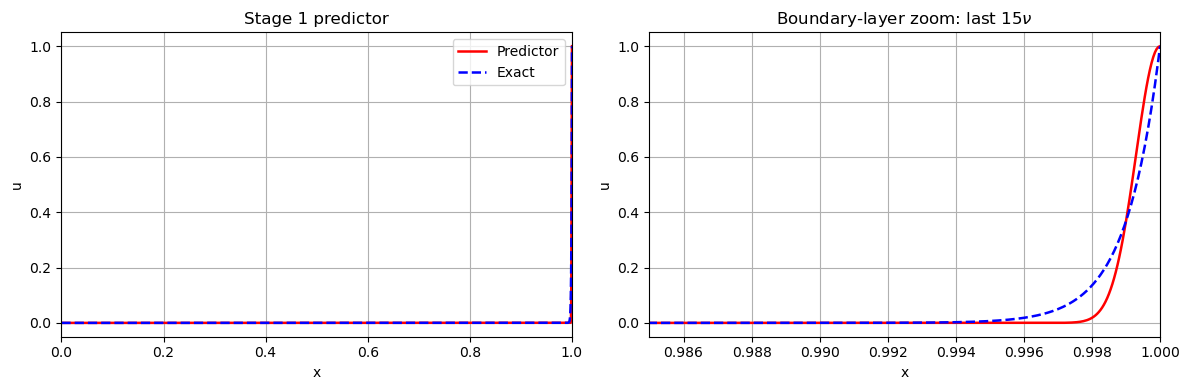

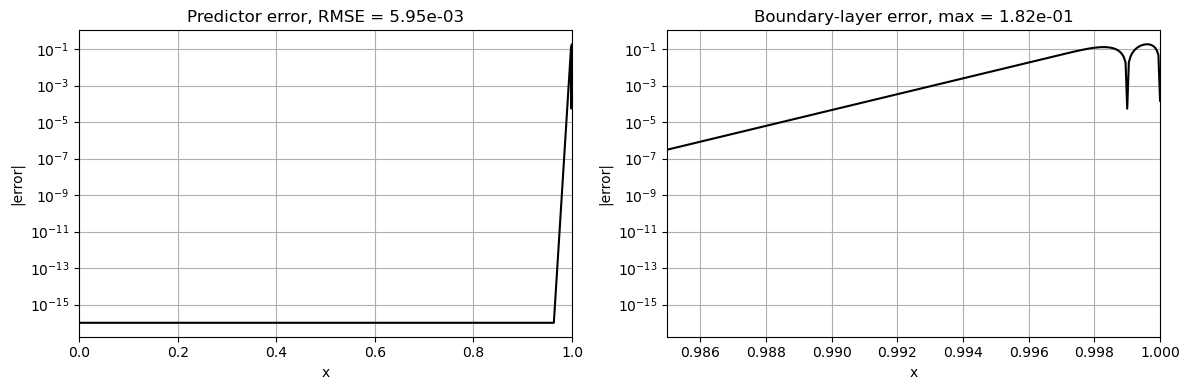

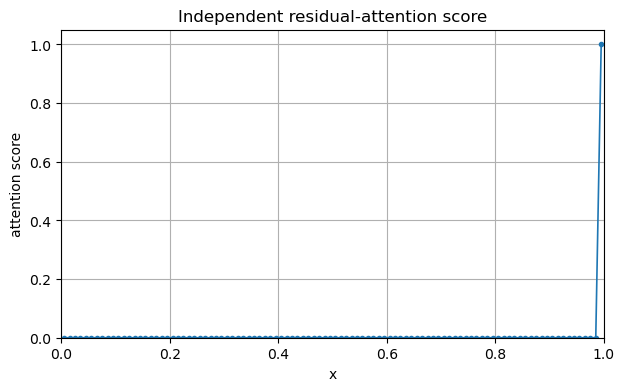

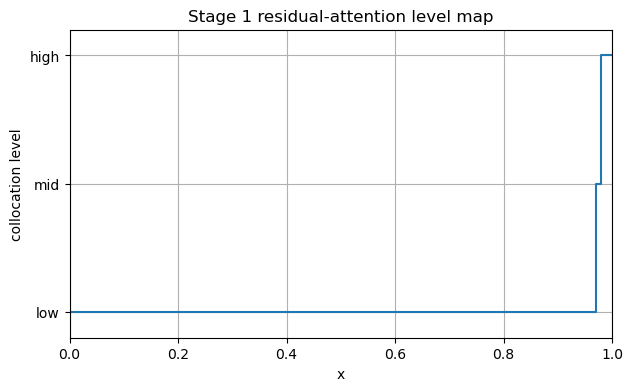

In [8]:
x_cent = 0.5 * (x_edges[:-1] + x_edges[1:])
x_zoom_L = max(XL, XR - 15 * nu)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x_plot, u_pred, 'r-', lw=1.8, label='Predictor')
ax[0].plot(x_plot, u_ex, 'b--', lw=1.8, label='Exact')
ax[0].grid(True); ax[0].set_xlim(XL, XR); ax[0].set_xlabel('x'); ax[0].set_ylabel('u')
ax[0].legend(); ax[0].set_title('Stage 1 predictor')
ax[1].plot(x_plot, u_pred, 'r-', lw=1.8)
ax[1].plot(x_plot, u_ex, 'b--', lw=1.8)
ax[1].grid(True); ax[1].set_xlim(x_zoom_L, XR); ax[1].set_xlabel('x'); ax[1].set_ylabel('u')
ax[1].set_title(r'Boundary-layer zoom: last $15\nu$')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, lim, title in [(ax[0], (XL, XR), f'Predictor error, RMSE = {rmse_predictor:.2e}'),
                       (ax[1], (x_zoom_L, XR), f'Boundary-layer error, max = {maxerr_predictor:.2e}')]:
    a.semilogy(x_plot, np.maximum(np.abs(err), 1e-16), 'k-', lw=1.5)
    a.grid(True); a.set_xlim(*lim); a.set_xlabel('x'); a.set_ylabel('|error|'); a.set_title(title)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4)); plt.plot(x_cent, attention_score, '-o', lw=1.2, ms=3)
plt.grid(True); plt.xlim(XL, XR); plt.ylim(0,1.05); plt.xlabel('x'); plt.ylabel('attention score')
plt.title('Independent residual-attention score'); plt.show()

plt.figure(figsize=(7,4)); plt.step(x_edges, np.r_[level_map, level_map[-1]], where='post', lw=1.5)
plt.grid(True); plt.xlim(XL, XR); plt.ylim(0.8,3.2); plt.yticks([1,2,3], ['low','mid','high'])
plt.xlabel('x'); plt.ylabel('collocation level'); plt.title('Stage 1 residual-attention level map'); plt.show()